In [14]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os



import importlib

In [2]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [9]:

df_paths_2 = "predsarrays_offset_half/"

df_neg_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/"
df_pos_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/"

df_neg = pd.read_csv(f"{df_neg_base_path+df_paths_2}"+"df_matched")
df_pos =  pd.read_csv(f"{df_pos_base_path+df_paths_2}"+"df_matched")

In [5]:
df_pos = df_pos.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])

In [10]:
df_pos[df_pos['dist_to_implant']>50]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
12,12,12,ztf_20221020148032_000686_zg_c07_x_0013.,4,pos,946.000000,716.000000,1,729.0,2433.0,...,1,4,6.0,[],0.0,256.017578,1212.0,729.0,1.005,3.0
138,138,138,ztf_20221020294271_000449_zr_c16_x_0020.,3,pos,1000.500000,1967.000000,2,1979.0,2295.0,...,0,3,7.0,[],0.0,198.522669,1209.0,1980.0,2.000,6.0
143,143,143,ztf_20221020294271_000449_zr_c16_x_0020.,3,pos,1591.500000,1967.000000,2,1979.0,2295.0,...,0,3,7.0,[],0.0,182.831206,1784.0,1988.0,2.000,3.0
196,196,196,ztf_20221020148032_000686_zg_c03_x_0011.,2,pos,1613.000000,178.000000,1,191.0,1932.0,...,1,2,7.0,[],0.0,175.025712,1798.0,191.0,1.200,8.0
211,211,211,ztf_20221020148032_000686_zg_c03_x_0011.,2,pos,3028.822581,474.725806,62,561.0,2378.0,...,23,2,3.0,[],0.0,659.358762,2449.0,190.0,1.050,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1118,1118,1118,ztf_20221020154120_000640_zi_c08_x_0014.,3,pos,1611.636364,2046.090909,11,2054.0,495.0,...,0,3,7.0,[1119],0.0,233.008105,1783.0,1888.0,1.400,3.0
1119,1119,1119,ztf_20221020154120_000640_zi_c08_x_0014.,3,pos,1612.000000,2042.500000,6,2054.0,495.0,...,0,3,7.0,[1118],1.0,230.176563,1783.0,1888.0,1.400,3.0
1155,1155,1155,ztf_20221020154120_000640_zi_c08_x_0014.,2,pos,123.500000,2451.000000,2,2458.0,2336.0,...,0,2,11.0,[],0.0,52.585644,81.0,2458.0,1.300,8.0
1156,1156,1156,ztf_20221020154120_000640_zi_c08_x_0014.,2,pos,202.000000,2451.000000,1,2458.0,2336.0,...,0,2,11.0,[],0.0,103.585713,133.0,2528.0,2.000,3.0


In [8]:
rff.inspect_stamp_and_map?

Signature:
rff.inspect_stamp_and_map(
    df,
    index,
    eff=True,
    neweff='new_eff_data/',
    posneg=None,
    size=10,
    column=None,
    nn_or_imp='nn',
    thr=True,
    star=False,
    direcname='1020',
    pdirec='predsarrays',
)
Docstring: for efficiency data
File:      ~/rwe/review_findings_functions.py
Type:      function

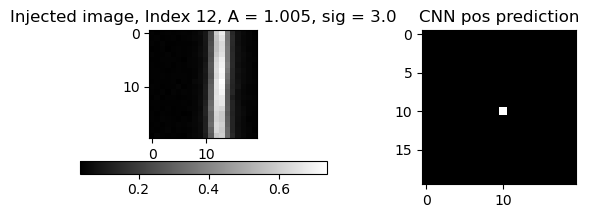

ztf_20221020148032_000686_zg_c07_x_0013. 4


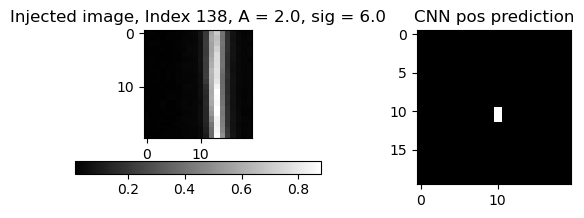

ztf_20221020294271_000449_zr_c16_x_0020. 3


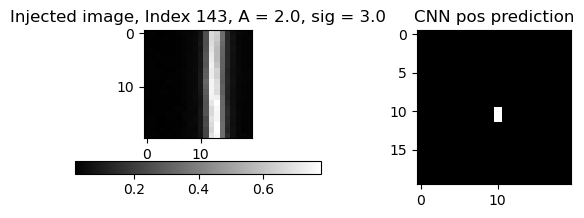

ztf_20221020294271_000449_zr_c16_x_0020. 3


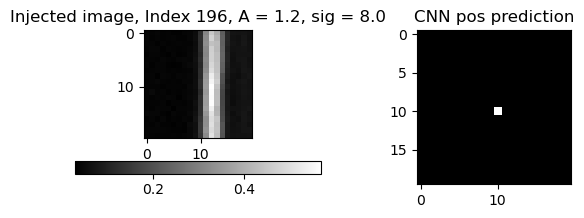

ztf_20221020148032_000686_zg_c03_x_0011. 2


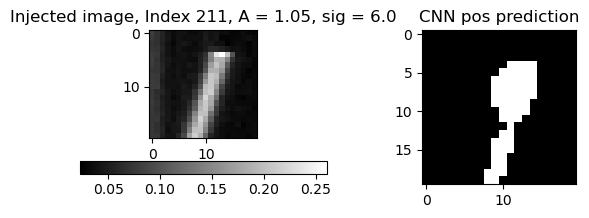

ztf_20221020148032_000686_zg_c03_x_0011. 2


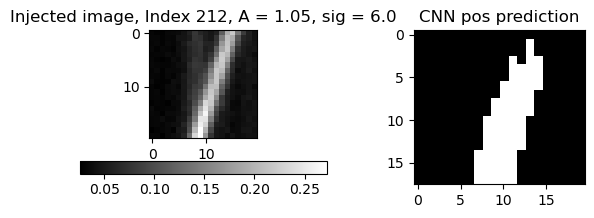

ztf_20221020148032_000686_zg_c03_x_0011. 2


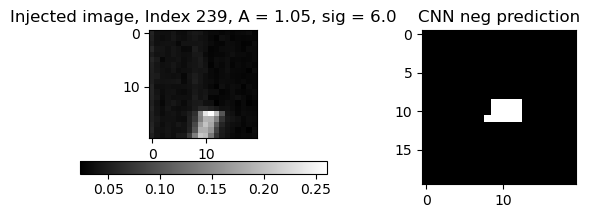

ztf_20221020148032_000686_zg_c03_x_0011. 2


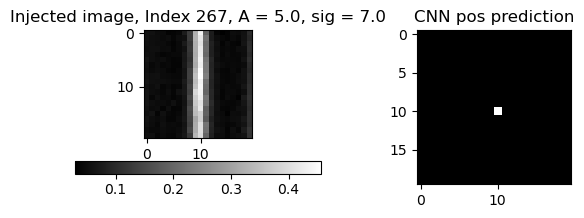

ztf_20221020148032_000686_zg_c16_x_0014. 3


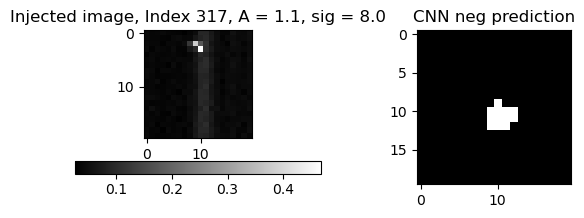

ztf_20221020148032_000686_zg_c16_x_0014. 3


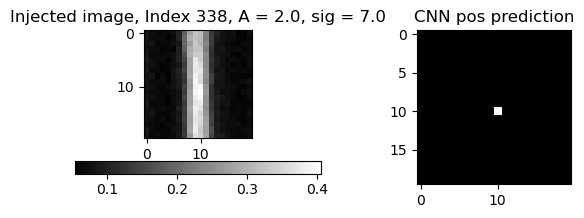

ztf_20221020148032_000686_zg_c03_x_0011. 3


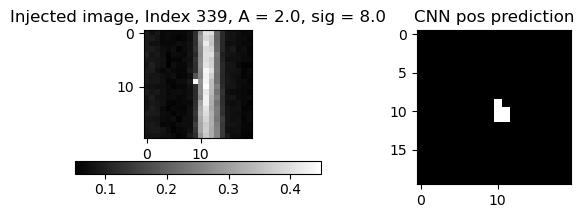

ztf_20221020148032_000686_zg_c03_x_0011. 3


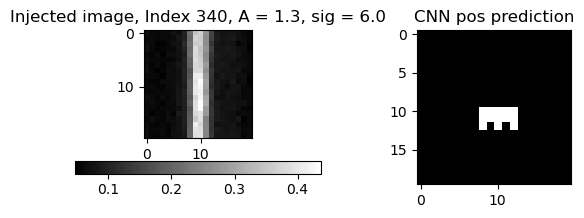

ztf_20221020148032_000686_zg_c03_x_0011. 3


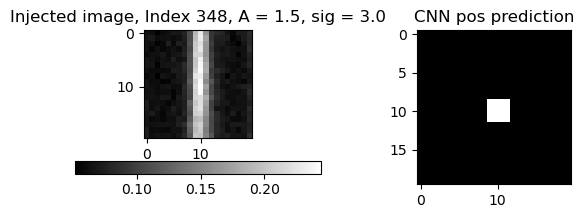

ztf_20221020148032_000686_zg_c03_x_0011. 3


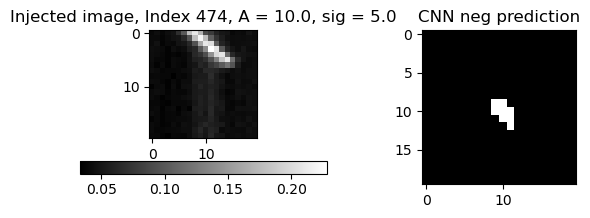

ztf_20221020154120_000640_zi_c11_x_0015. 2


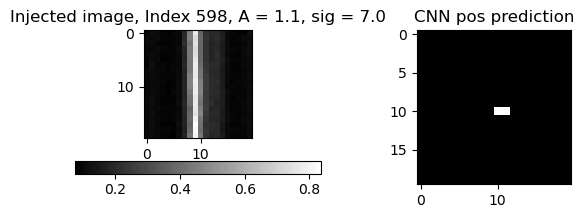

ztf_20221020154120_000640_zi_c15_x_0028. 1


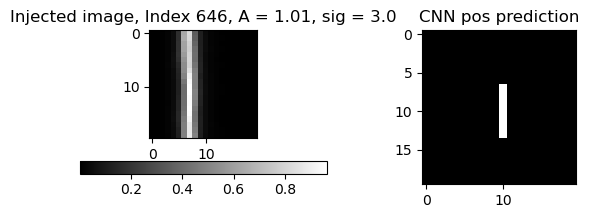

ztf_20221020294271_000449_zr_c16_x_0020. 2


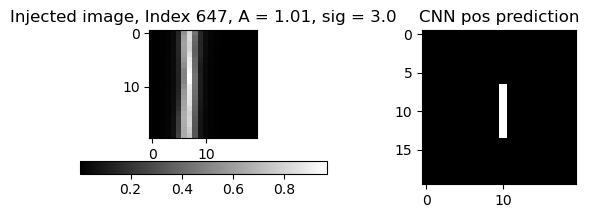

ztf_20221020294271_000449_zr_c16_x_0020. 2


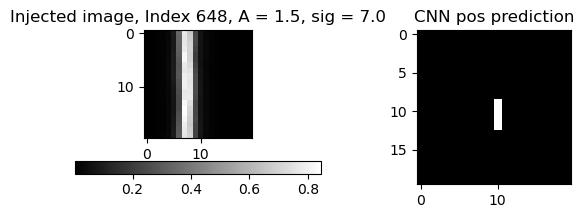

ztf_20221020294271_000449_zr_c16_x_0020. 2


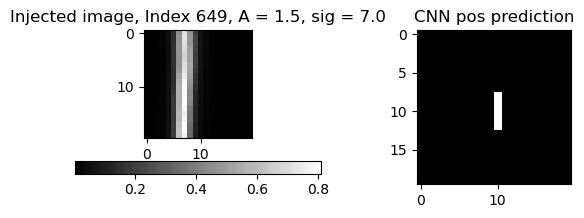

ztf_20221020294271_000449_zr_c16_x_0020. 2


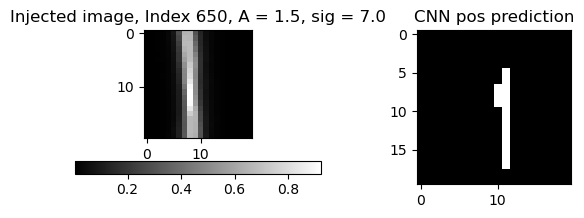

ztf_20221020294271_000449_zr_c16_x_0020. 2


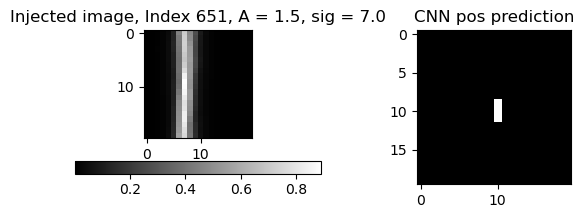

ztf_20221020294271_000449_zr_c16_x_0020. 2


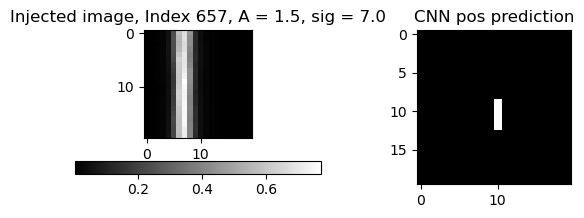

ztf_20221020294271_000449_zr_c16_x_0020. 2


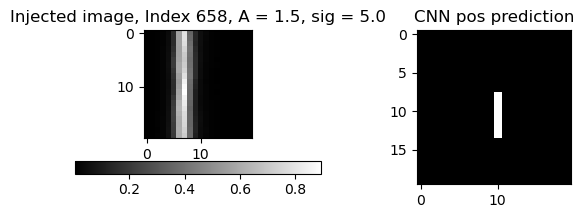

ztf_20221020294271_000449_zr_c16_x_0020. 2


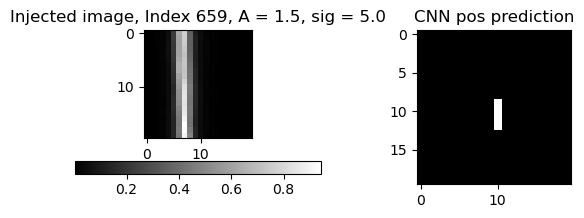

ztf_20221020294271_000449_zr_c16_x_0020. 2


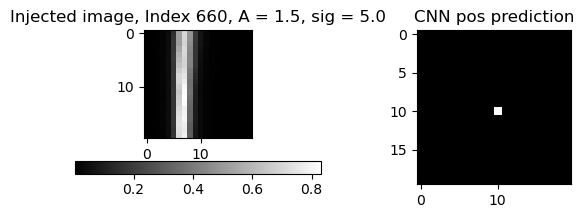

ztf_20221020294271_000449_zr_c16_x_0020. 2


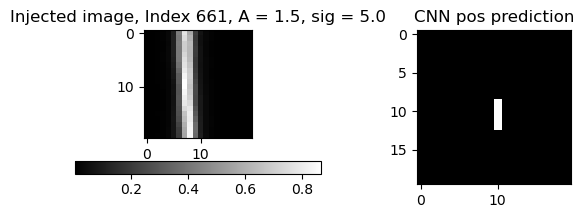

ztf_20221020294271_000449_zr_c16_x_0020. 2


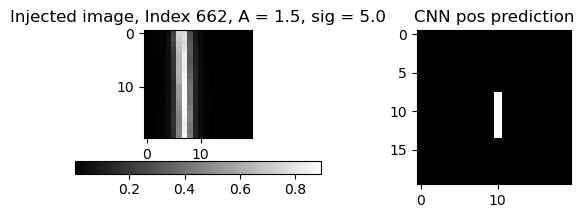

ztf_20221020294271_000449_zr_c16_x_0020. 2


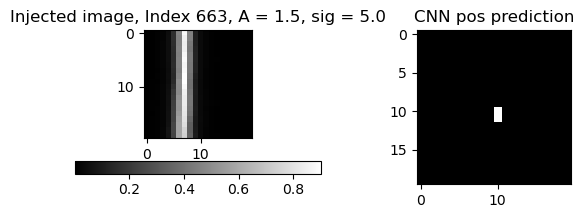

ztf_20221020294271_000449_zr_c16_x_0020. 2


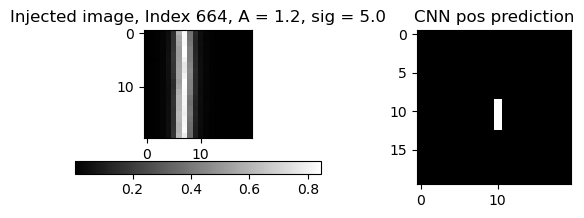

ztf_20221020294271_000449_zr_c16_x_0020. 2


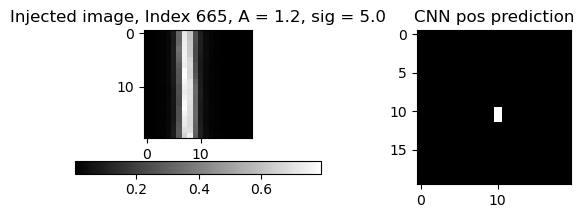

ztf_20221020294271_000449_zr_c16_x_0020. 2


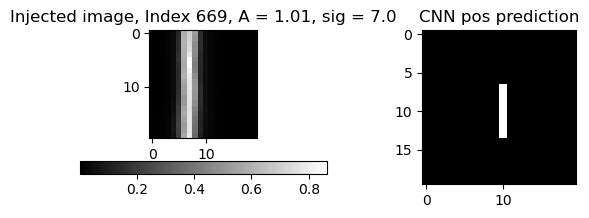

ztf_20221020294271_000449_zr_c16_x_0020. 2


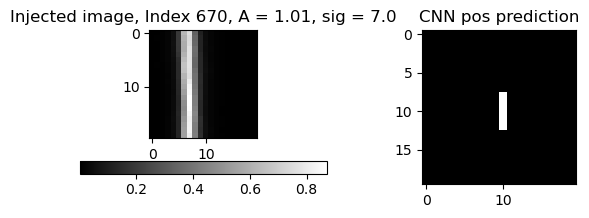

ztf_20221020294271_000449_zr_c16_x_0020. 2


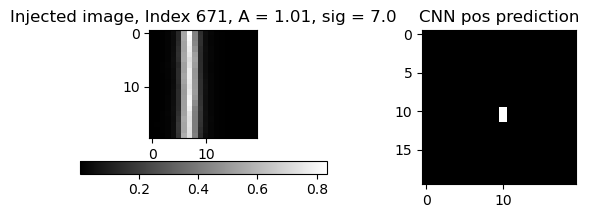

ztf_20221020294271_000449_zr_c16_x_0020. 2


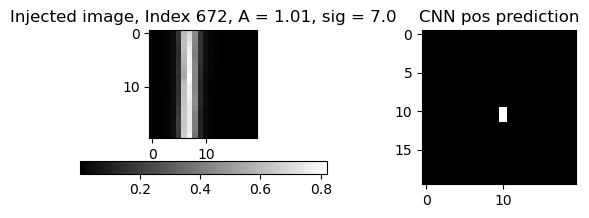

ztf_20221020294271_000449_zr_c16_x_0020. 2


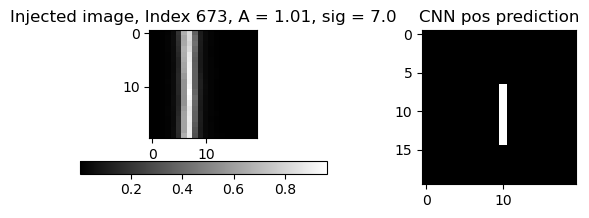

ztf_20221020294271_000449_zr_c16_x_0020. 2


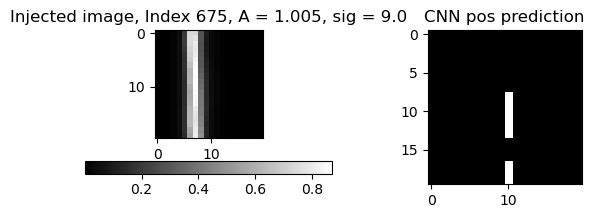

ztf_20221020294271_000449_zr_c16_x_0020. 2


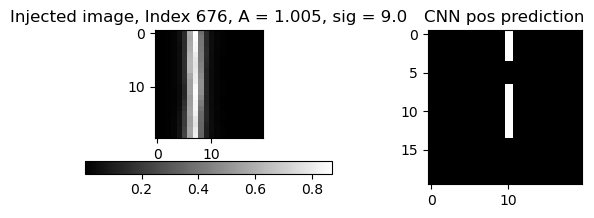

ztf_20221020294271_000449_zr_c16_x_0020. 2


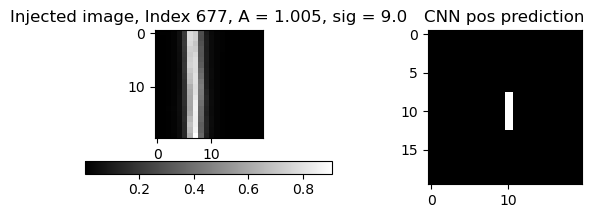

ztf_20221020294271_000449_zr_c16_x_0020. 2


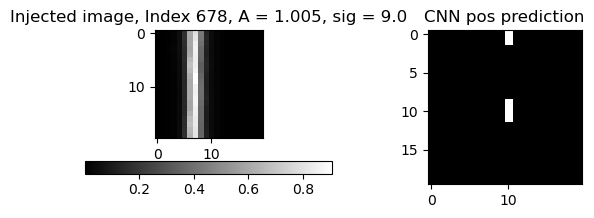

ztf_20221020294271_000449_zr_c16_x_0020. 2


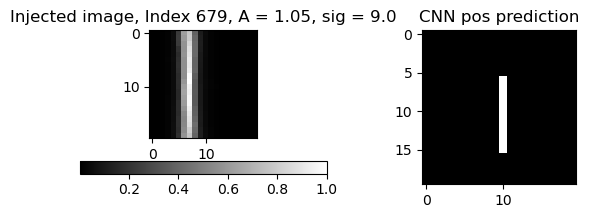

ztf_20221020294271_000449_zr_c16_x_0020. 2


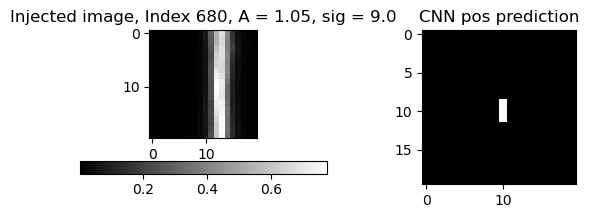

ztf_20221020294271_000449_zr_c16_x_0020. 2


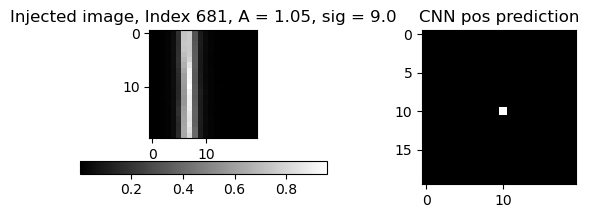

ztf_20221020294271_000449_zr_c16_x_0020. 2


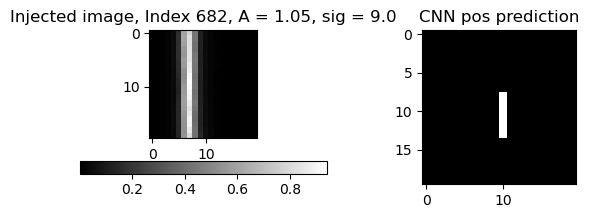

ztf_20221020294271_000449_zr_c16_x_0020. 2


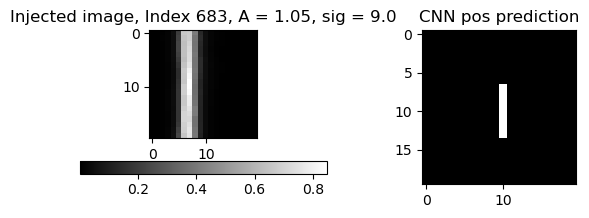

ztf_20221020294271_000449_zr_c16_x_0020. 2


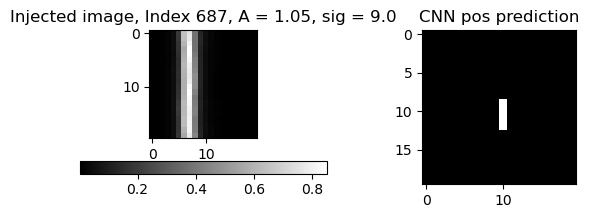

ztf_20221020294271_000449_zr_c16_x_0020. 2


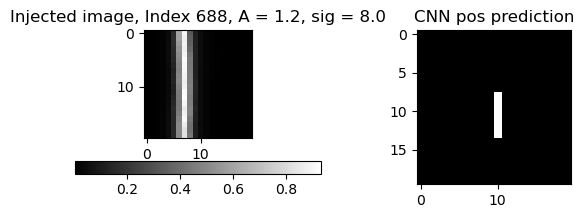

ztf_20221020294271_000449_zr_c16_x_0020. 2


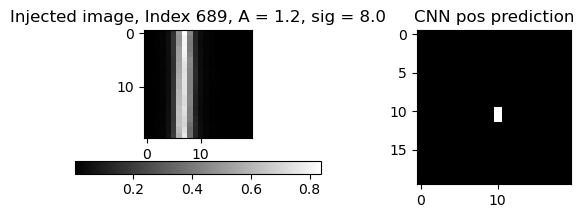

ztf_20221020294271_000449_zr_c16_x_0020. 2


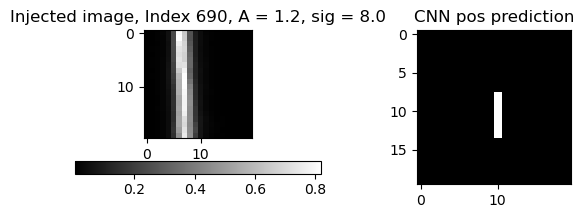

ztf_20221020294271_000449_zr_c16_x_0020. 2


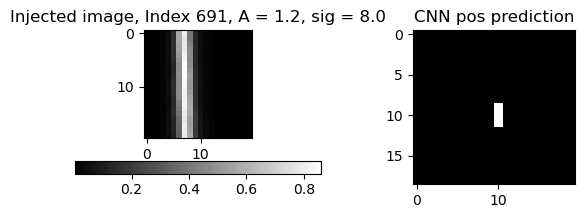

ztf_20221020294271_000449_zr_c16_x_0020. 2


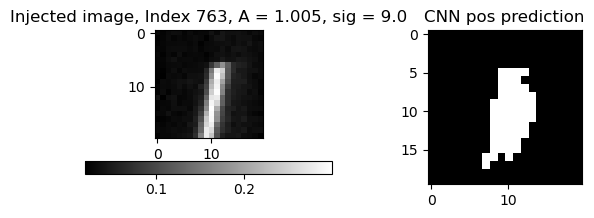

ztf_20221020148032_000686_zg_c16_x_0014. 4


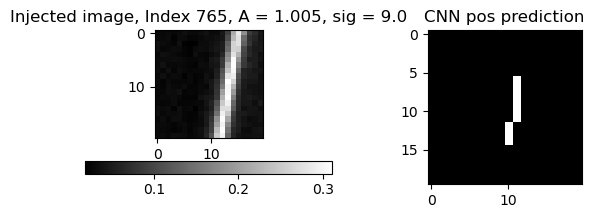

ztf_20221020148032_000686_zg_c16_x_0014. 4


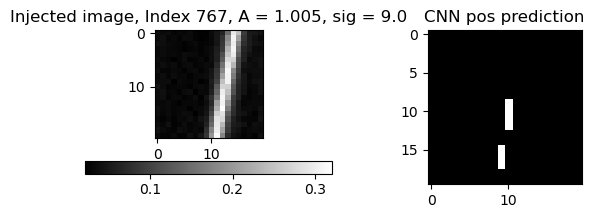

ztf_20221020148032_000686_zg_c16_x_0014. 4


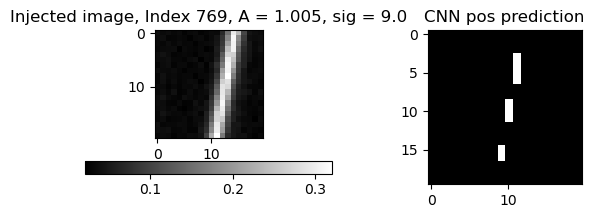

ztf_20221020148032_000686_zg_c16_x_0014. 4


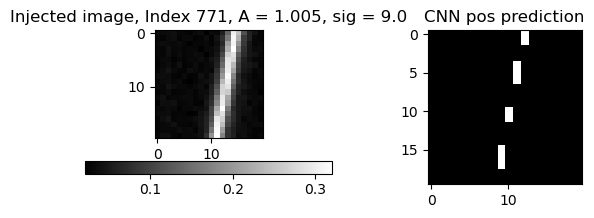

ztf_20221020148032_000686_zg_c16_x_0014. 4


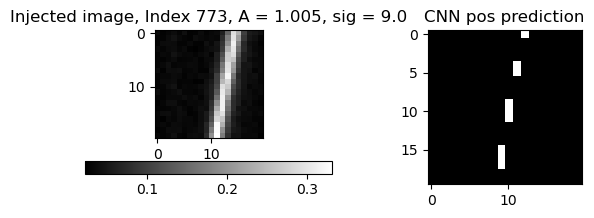

ztf_20221020148032_000686_zg_c16_x_0014. 4


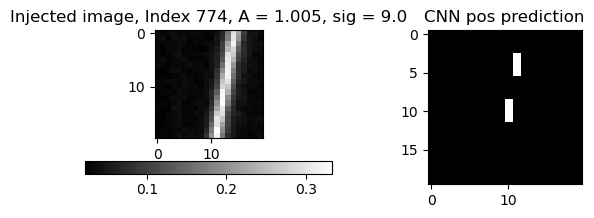

ztf_20221020148032_000686_zg_c16_x_0014. 4


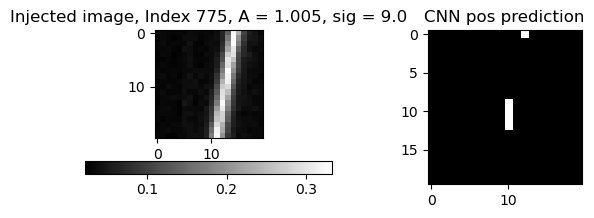

ztf_20221020148032_000686_zg_c16_x_0014. 4


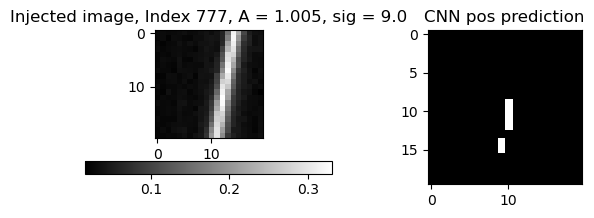

ztf_20221020148032_000686_zg_c16_x_0014. 4


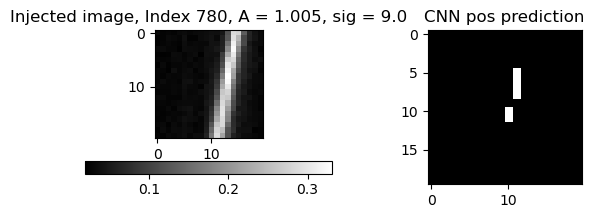

ztf_20221020148032_000686_zg_c16_x_0014. 4


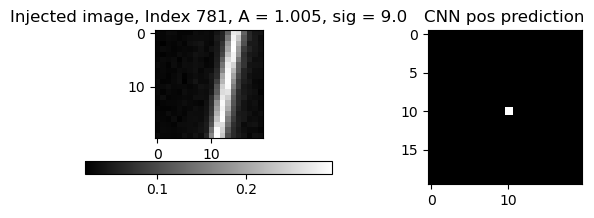

ztf_20221020148032_000686_zg_c16_x_0014. 4


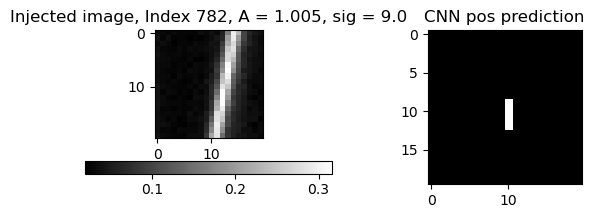

ztf_20221020148032_000686_zg_c16_x_0014. 4


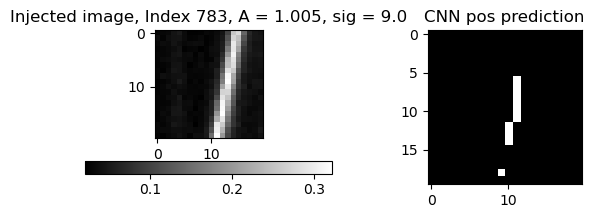

ztf_20221020148032_000686_zg_c16_x_0014. 4


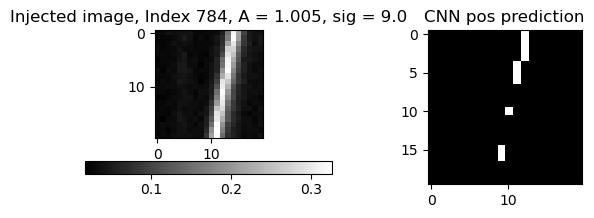

ztf_20221020148032_000686_zg_c16_x_0014. 4


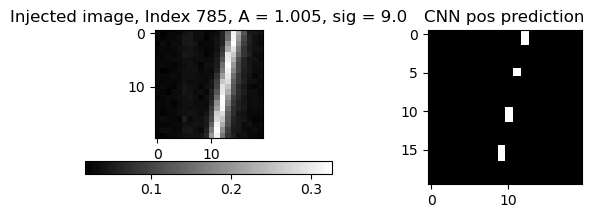

ztf_20221020148032_000686_zg_c16_x_0014. 4


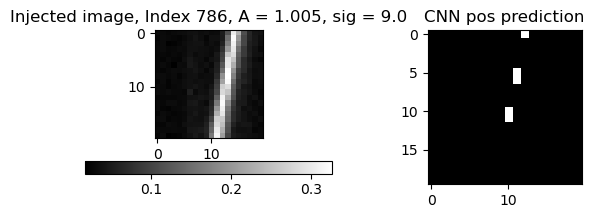

ztf_20221020148032_000686_zg_c16_x_0014. 4


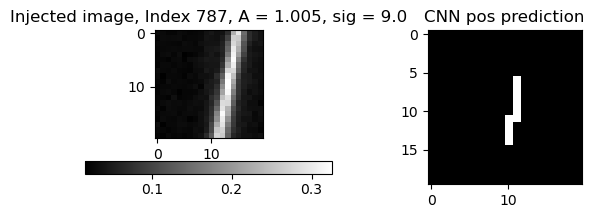

ztf_20221020148032_000686_zg_c16_x_0014. 4


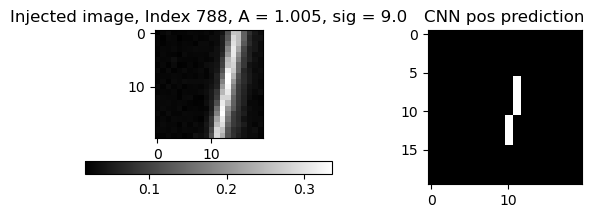

ztf_20221020148032_000686_zg_c16_x_0014. 4


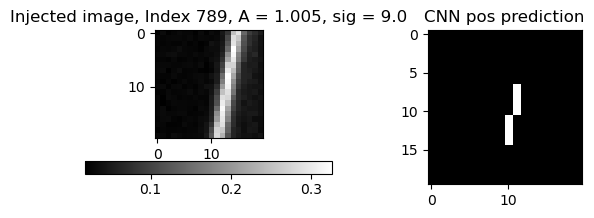

ztf_20221020148032_000686_zg_c16_x_0014. 4


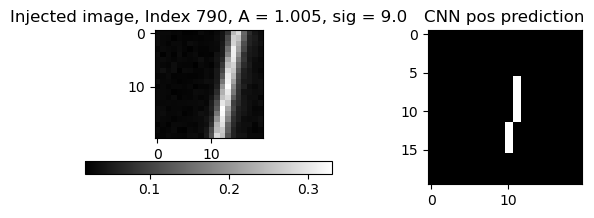

ztf_20221020148032_000686_zg_c16_x_0014. 4


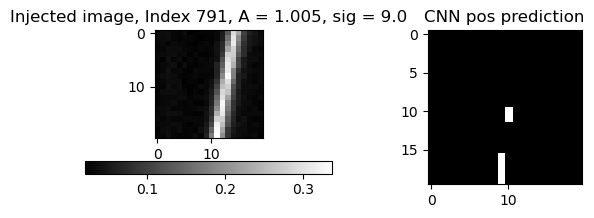

ztf_20221020148032_000686_zg_c16_x_0014. 4


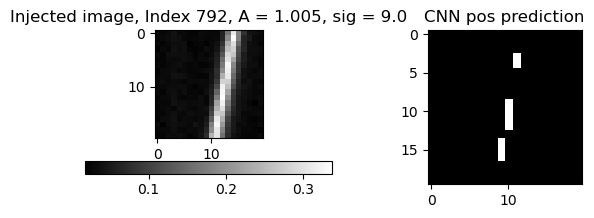

ztf_20221020148032_000686_zg_c16_x_0014. 4


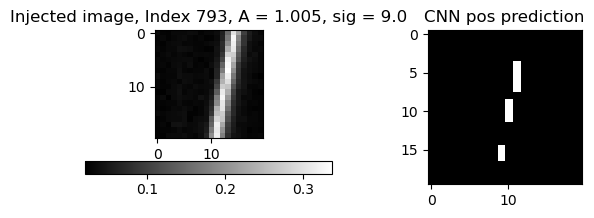

ztf_20221020148032_000686_zg_c16_x_0014. 4


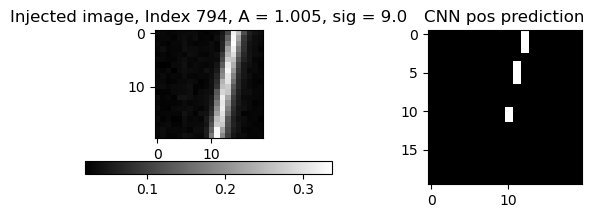

ztf_20221020148032_000686_zg_c16_x_0014. 4


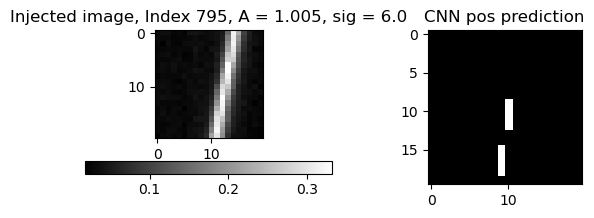

ztf_20221020148032_000686_zg_c16_x_0014. 4


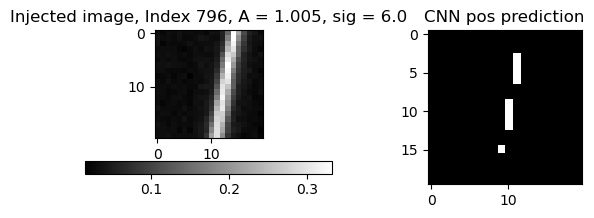

ztf_20221020148032_000686_zg_c16_x_0014. 4


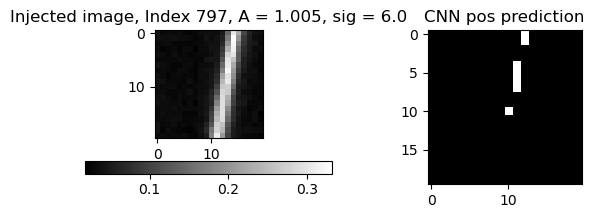

ztf_20221020148032_000686_zg_c16_x_0014. 4


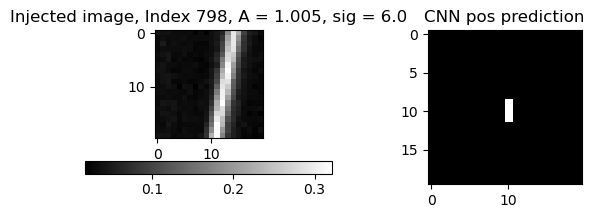

ztf_20221020148032_000686_zg_c16_x_0014. 4


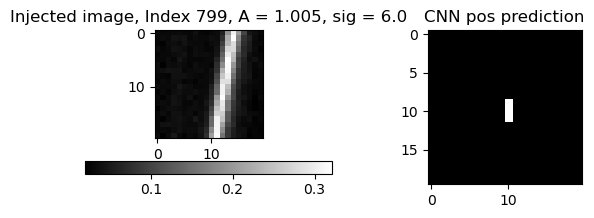

ztf_20221020148032_000686_zg_c16_x_0014. 4


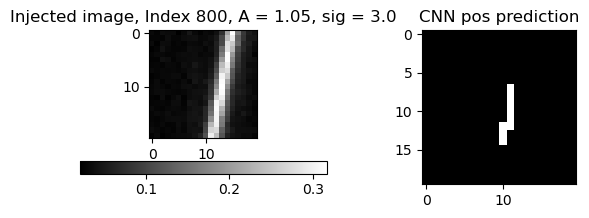

ztf_20221020148032_000686_zg_c16_x_0014. 4


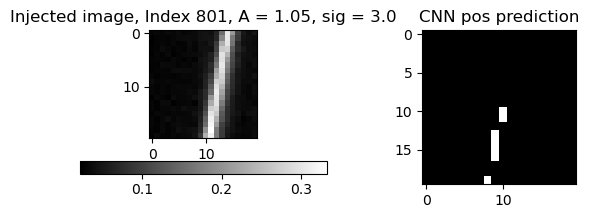

ztf_20221020148032_000686_zg_c16_x_0014. 4


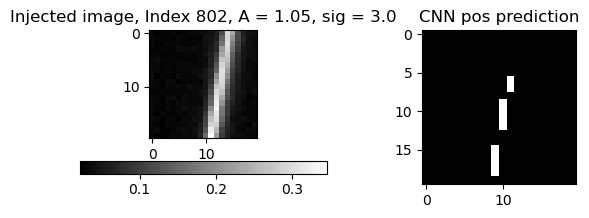

ztf_20221020148032_000686_zg_c16_x_0014. 4


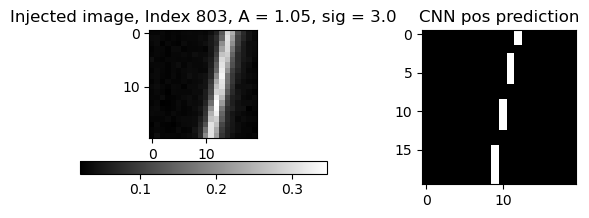

ztf_20221020148032_000686_zg_c16_x_0014. 4


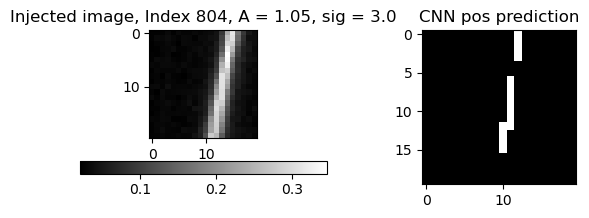

ztf_20221020148032_000686_zg_c16_x_0014. 4


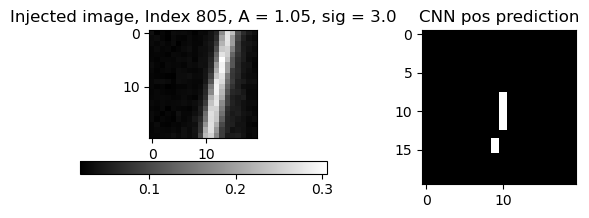

ztf_20221020148032_000686_zg_c16_x_0014. 4


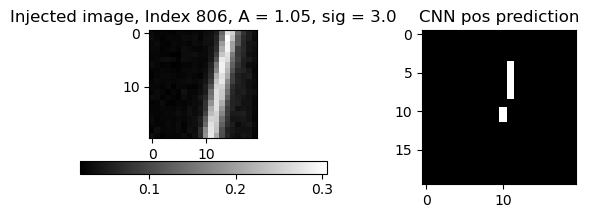

ztf_20221020148032_000686_zg_c16_x_0014. 4


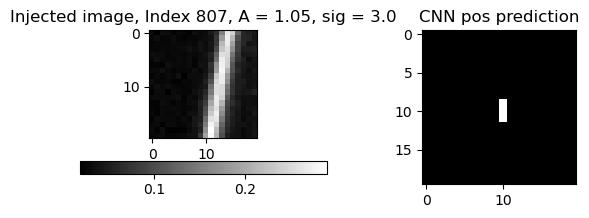

ztf_20221020148032_000686_zg_c16_x_0014. 4


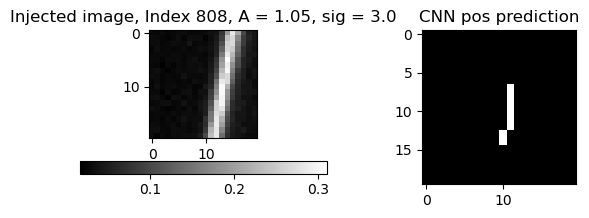

ztf_20221020148032_000686_zg_c16_x_0014. 4


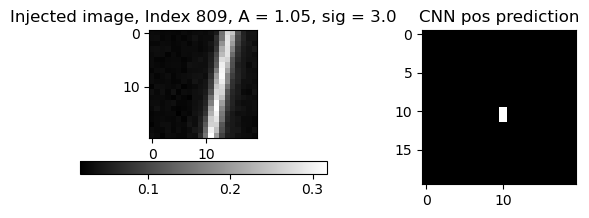

ztf_20221020148032_000686_zg_c16_x_0014. 4


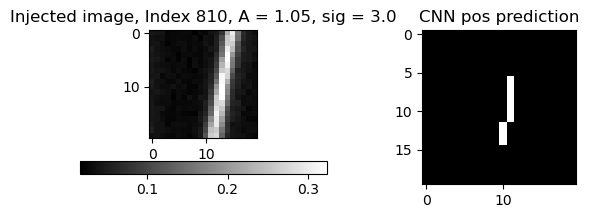

ztf_20221020148032_000686_zg_c16_x_0014. 4


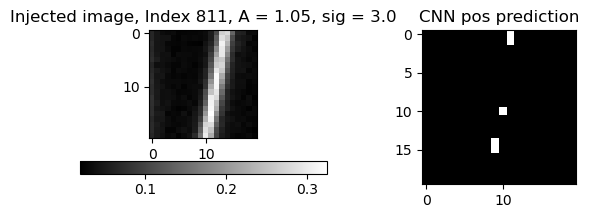

ztf_20221020148032_000686_zg_c16_x_0014. 4


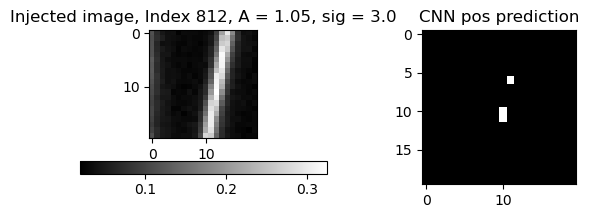

ztf_20221020148032_000686_zg_c16_x_0014. 4


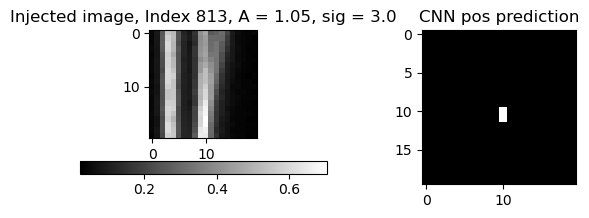

ztf_20221020148032_000686_zg_c16_x_0014. 4


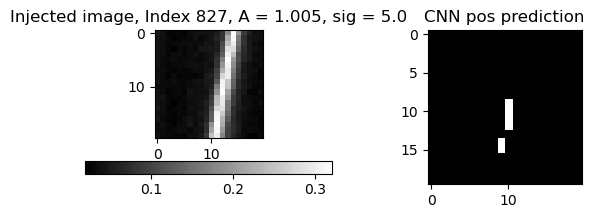

ztf_20221020148032_000686_zg_c16_x_0014. 4


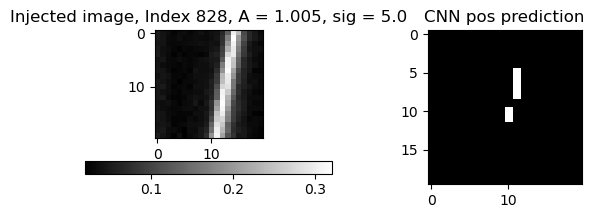

ztf_20221020148032_000686_zg_c16_x_0014. 4


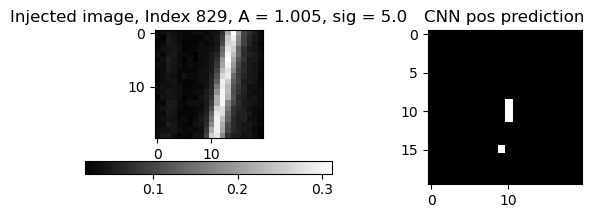

ztf_20221020148032_000686_zg_c16_x_0014. 4


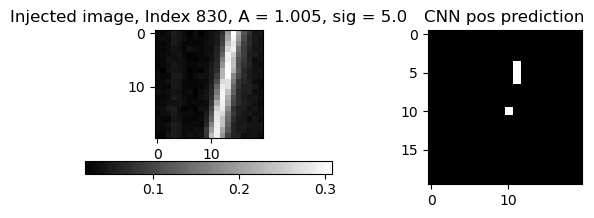

ztf_20221020148032_000686_zg_c16_x_0014. 4


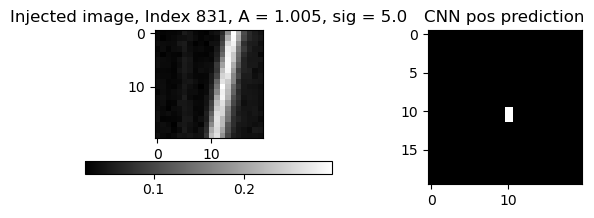

ztf_20221020148032_000686_zg_c16_x_0014. 4


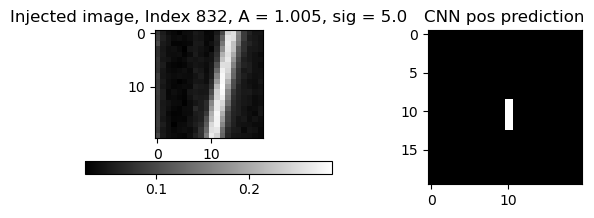

ztf_20221020148032_000686_zg_c16_x_0014. 4


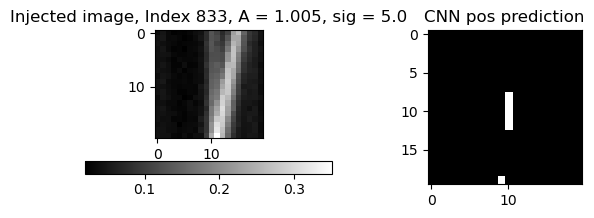

ztf_20221020148032_000686_zg_c16_x_0014. 4


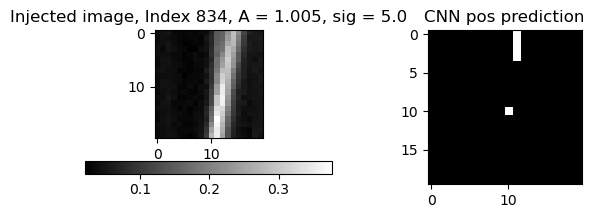

ztf_20221020148032_000686_zg_c16_x_0014. 4


In [13]:
for index in df_pos[df_pos['dist_to_implant']>50].index[0:100]:
    rff.inspect_stamp_and_map(df_pos, index, posneg='pos',pdirec=df_paths_2)
    print(df_pos.loc[index, "filename"], df_pos.loc[index, "quad"])

In [16]:
def get_histtable(df):
    '''
    sort by the thing you want, it keeps the last (biggest)
    '''
    data = df.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")["A_from_implant"]
    print(len(data))
    return data

def make_bar(df, label, binbounds, ax, alpha=.5):
    data = get_histtable(df)
    hist, bin_edges = np.histogram(data,binbounds)
    return ax.bar(range(len(hist)),hist,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist)], alpha=alpha, label=label)

base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/"


both = pd.concat([df_neg[df_neg['type']=='neg'],df_pos[df_pos['type']=='pos']], ignore_index=True)

df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/df_implants_pos")
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")


binbounds = list(np.unique(np.concatenate([df_implants_neg["A_from_implant"],
                                           [1],
                                           df_implants_pos["A_from_implant"],
                                           [np.unique(df_implants_pos["A_from_implant"])[-1]+.002]]))-.001)


In [ ]:
both = pd.concat([df_neg[df_neg['type']=='neg'],df_pos[df_pos['type']=='pos']], ignore_index=True)


In [18]:

df_paths_2 = "predsarrays_newrange/"

df_neg_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/"
df_pos_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/"

df_neg2 = pd.read_csv(f"{df_neg_base_path+df_paths_2}"+"df_matched")
df_pos2 =  pd.read_csv(f"{df_pos_base_path+df_paths_2}"+"df_matched")
both2 = pd.concat([df_neg2[df_neg2['type']=='neg'],df_pos2[df_pos2['type']=='pos']], ignore_index=True)


In [20]:
df_paths_2 = "predsarrays_dup_3/"

df_neg3 = pd.read_csv(f"{df_neg_base_path+df_paths_2}"+"df_matched")
df_pos3 =  pd.read_csv(f"{df_pos_base_path+df_paths_2}"+"df_matched")
both3 = pd.concat([df_neg3[df_neg3['type']=='neg'],df_pos3[df_pos3['type']=='pos']], ignore_index=True)


3469
3161
2720


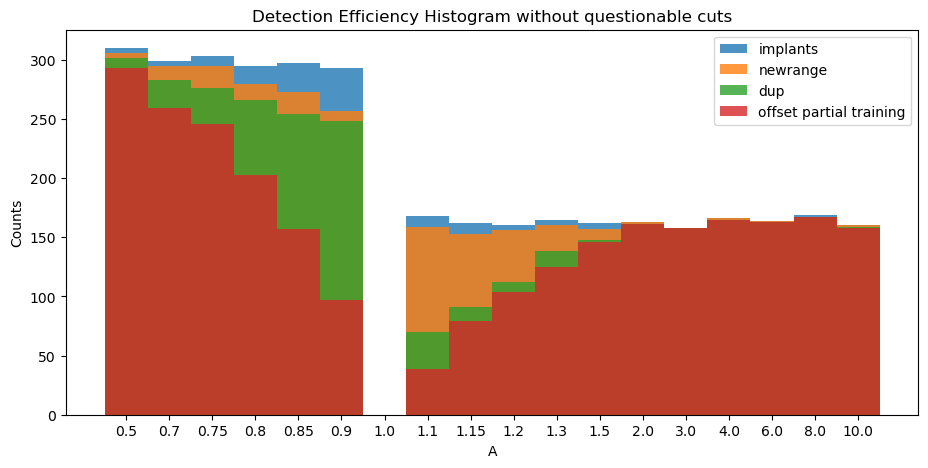

In [31]:
bins = binbounds
fig,ax = plt.subplots(figsize=(11,5))
alpha = .8

implants = np.concatenate([df_implants_neg["A_from_implant"],df_implants_pos["A_from_implant"]])
hist_implants, bin_edges = np.histogram(implants,bins) # make the histogram
ax.bar(range(len(hist_implants)),hist_implants,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist_implants)], alpha=alpha, label="implants")




make_bar(both2, "newrange", binbounds, ax, alpha=alpha)
make_bar(both3, "dup", binbounds, ax, alpha=alpha)
make_bar(both, "offset partial training", binbounds, ax, alpha=alpha)


# make_bar(noedges, "reduced edges", binbounds, ax, alpha=alpha)
# make_bar(matched[matched["Diff"]<10], "diff<10", binbounds, ax, alpha=alpha)
# make_bar(matched[matched["Diff"]<5], "diff<5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>.5].sort_values("snr_local"), "snr>0.5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>1].sort_values("snr_local"), "snr>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>3].sort_values("snr_local"), "snr>3", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>1], "detection size>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>3], "detection size>3", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>5], "detection size>4", binbounds, ax, alpha=alpha)


plt.title("Detection Efficiency Histogram without questionable cuts")
plt.ylabel("Counts")
plt.xlabel("A")
plt.legend()
plt.show()



In [16]:



fpath_sat = "/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/"

image_path = fpath_sat + "images/"
info_path = fpath_sat + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_sat_stamps = trans_arr
        all_sat_stamps_info = infos_arr
    else:
        all_sat_stamps = np.concatenate((all_sat_stamps, trans_arr), axis=0)
        all_sat_stamps_info = np.concatenate((all_sat_stamps_info, infos_arr), axis=0)

        

sat_stamps.npy
(1775, 20, 20)
(1775, 6)
